In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
os.makedirs('/content/drive/MyDrive/football_project/data/raw', exist_ok=True)
os.makedirs('/content/drive/MyDrive/football_project/data/processed', exist_ok=True)
os.makedirs('/content/drive/MyDrive/football_project/models', exist_ok=True)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("sklearn:", sklearn.__version__)

pandas: 2.2.3
numpy: 2.4.6
sklearn: 1.6.1


In [5]:
from google.colab import drive
drive.mount('/content/drive')

import os
RAW_DIR = '/content/drive/MyDrive/football_project/data/raw'
os.makedirs(RAW_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#Первичный осмотр данных
import pandas as pd

RAW_DIR = '/content/drive/MyDrive/football_project/data/raw'

players = pd.read_csv(f'{RAW_DIR}/players.csv')
valuations = pd.read_csv(f'{RAW_DIR}/player_valuations.csv')
appearances = pd.read_csv(f'{RAW_DIR}/appearances.csv')
clubs = pd.read_csv(f'{RAW_DIR}/clubs.csv')
competitions = pd.read_csv(f'{RAW_DIR}/competitions.csv')

for name, df in [('players', players), ('valuations', valuations),
                 ('appearances', appearances), ('clubs', clubs),
                 ('competitions', competitions)]:
    print(f"{name}")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print(df.head(2))
    print()

=== players ===
shape: (50149, 26)
columns: ['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']
   player_id first_name     last_name                name  last_season  \
0         10   Miroslav         Klose      Miroslav Klose         2015   
1         26      Roman  Weidenfeller  Roman Weidenfeller         2017   

   current_club_id         player_code country_of_birth city_of_birth  \
0              398      miroslav-klose           Poland       Opole     
1               16  roman-weidenfeller          Germany        Diez     

  country_of_citizenship  ...    

In [4]:
# Проверяем ключевые колонки в каждой таблице
for name, df in [('players', players), ('valuations', valuations), ('appearances', appearances), ('clubs', clubs), ('competitions', competitions)]:
    print(f"{name} ")
    print("Колонки:", list(df.columns))
    print("Пример ID:", df.iloc[0].to_dict() if 'player_id' in df.columns or 'club_id' in df.columns else '—')
    print()

players 
Колонки: ['player_id', 'first_name', 'last_name', 'name', 'last_season', 'current_club_id', 'player_code', 'country_of_birth', 'city_of_birth', 'country_of_citizenship', 'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm', 'contract_expiration_date', 'agent_name', 'image_url', 'international_caps', 'international_goals', 'current_national_team_id', 'url', 'current_club_domestic_competition_id', 'current_club_name', 'market_value_in_eur', 'highest_market_value_in_eur']
Пример ID: {'player_id': 10, 'first_name': 'Miroslav', 'last_name': 'Klose', 'name': 'Miroslav Klose', 'last_season': 2015, 'current_club_id': 398, 'player_code': 'miroslav-klose', 'country_of_birth': 'Poland', 'city_of_birth': 'Opole\xa0\xa0', 'country_of_citizenship': 'Germany', 'date_of_birth': '1978-06-09 00:00:00', 'sub_position': 'Centre-Forward', 'position': 'Attack', 'foot': 'right', 'height_in_cm': 184.0, 'contract_expiration_date': nan, 'agent_name': 'ASBW Sport Marketing', 'image_url': 

In [7]:
# 1. Базовая информация из players
players_sub = players[[
    'player_id', 'name', 'date_of_birth', 'position', 'sub_position',
    'country_of_citizenship', 'foot', 'height_in_cm',
    'current_club_id', 'current_club_name',
    'current_club_domestic_competition_id',
    'market_value_in_eur', 'highest_market_value_in_eur'
]].copy()

print("Игроков в players:", len(players_sub))
print("С непустой ценой:", players_sub['market_value_in_eur'].notna().sum())

# 2. Суммарная статистика по матчам
stats = (appearances
         .groupby('player_id')
         .agg(goals=('goals', 'sum'),
              assists=('assists', 'sum'),
              appearances=('appearance_id', 'count'),
              minutes_played=('minutes_played', 'sum'),
              yellow_cards=('yellow_cards', 'sum'),
              red_cards=('red_cards', 'sum'))
         .reset_index())
print("Игроков со статистикой:", len(stats))

# 3. Справочник лиг из competitions
# В competitions колонки: competition_id, name, type, country_name и т.д.
# Нам нужно competition_id + name + country_name
comps_sub = competitions[['competition_id', 'name', 'type', 'country_name']].rename(
    columns={'name': 'competition_name'})

# У players есть current_club_domestic_competition_id - это код лиги ('IT1', 'BE1', ...).
# В competitions поле competition_id — тоже коды ('IT1', 'BE1', ...). Проверим формат:
print("Пример competition_id из competitions:", competitions['competition_id'].head(3).tolist())
print("Пример current_club_domestic_competition_id из players:",
      players['current_club_domestic_competition_id'].dropna().head(3).tolist())

# 4. Собираем всё вместе
df = (players_sub
      .merge(stats, on='player_id', how='left')
      .merge(comps_sub, left_on='current_club_domestic_competition_id',
             right_on='competition_id', how='left'))

# Убираем дублирующую колонку competition_id (если появилась)
if 'competition_id' in df.columns:
    df = df.drop(columns=['competition_id'])

print("Итоговая форма:", df.shape)
print("Дубли player_id:", df['player_id'].duplicated().sum())
df.head()

Игроков в players: 50149
С непустой ценой: 41528
Игроков со статистикой: 29531
Пример competition_id из competitions: ['A1', 'AFAC', 'AFCN']
Пример current_club_domestic_competition_id из players: ['IT1', 'L1', 'GR1']
Итоговая форма: (50149, 22)
Дубли player_id: 0


,player_id,name,date_of_birth,position,sub_position,country_of_citizenship,foot,height_in_cm,current_club_id,current_club_name,...,highest_market_value_in_eur,goals,assists,appearances,minutes_played,yellow_cards,red_cards,competition_name,type,country_name
0,10,Miroslav Klose,1978-06-09 00:00:00,Attack,Centre-Forward,Germany,right,184.0,398,Società Sportiva Lazio S.p.A.,...,30000000.0,48.0,25.0,136.0,8808.0,19.0,0.0,serie-a,domestic_league,Italy
1,26,Roman Weidenfeller,1980-08-06 00:00:00,Goalkeeper,Goalkeeper,Germany,left,190.0,16,Borussia Dortmund,...,8000000.0,0.0,0.0,152.0,13508.0,4.0,2.0,bundesliga,domestic_league,Germany
2,65,Dimitar Berbatov,1981-01-30 00:00:00,Attack,Centre-Forward,Bulgaria,NaN,NaN,1091,Panthessalonikios Athlitikos Omilos Konstantin...,...,34500000.0,38.0,13.0,122.0,8788.0,11.0,1.0,super-league-1,domestic_league,Greece
3,77,Lúcio,1978-05-08 00:00:00,Defender,Centre-Back,Brazil,NaN,NaN,506,Juventus FC,...,24500000.0,0.0,0.0,4.0,307.0,0.0,0.0,serie-a,domestic_league,Italy
4,80,Tom Starke,1981-03-18 00:00:00,Goalkeeper,Goalkeeper,Germany,right,194.0,27,Bayern Munich,...,3000000.0,0.0,0.0,12.0,1080.0,0.0,0.0,bundesliga,domestic_league,Germany


In [11]:
df['date_of_birth'] = pd.to_datetime(df['date_of_birth'])

# Возраст на сегодня (дата последней оценки в датасете неизвестна,
# поэтому считаем относительно текущей даты — для учебного проекта допустимо)
TODAY = pd.Timestamp.today()
df['age'] = ((TODAY - df['date_of_birth']).dt.days / 365.25).round(1)

print(df['age'].describe())
print("\nИгроков с возрастом < 16:", (df['age'] < 16).sum())
print("Игроков с возрастом > 45:", (df['age'] > 45).sum())

count    50100.000000
mean        29.428856
std          6.904841
min         15.700000
25%         23.900000
50%         28.600000
75%         33.800000
max         58.300000
Name: age, dtype: float64

Игроков с возрастом < 16: 1
Игроков с возрастом > 45: 1133


In [27]:
print("Пропуски до очистки (топ-15):")
print(df.isna().sum().sort_values(ascending=False).head(15))

#  Целевая переменная: market_value_in_eur
df_clean = df.dropna(subset=['market_value_in_eur']).copy()
print("\nПосле удаления без цены:", df_clean.shape)

#  Ключевые признаки
df_clean = df_clean.dropna(subset=['age', 'position'])
print("После удаления без возраста/позиции:", df_clean.shape)

# Статистика: если игрок не играл - 0
for col in ['goals', 'assists', 'appearances', 'minutes_played',
            'yellow_cards', 'red_cards']:
    df_clean[col] = df_clean[col].fillna(0)

#  Категориальные пропуски
df_clean['country_of_citizenship'] = df_clean['country_of_citizenship'].fillna('Unknown')
df_clean['competition_name'] = df_clean['competition_name'].fillna('Unknown')
df_clean['sub_position'] = df_clean['sub_position'].fillna('Unknown')
df_clean['foot'] = df_clean['foot'].fillna('Unknown')

# Высота: заполним медианой (немного пропусков)
df_clean['height_in_cm'] = df_clean['height_in_cm'].fillna(
    df_clean['height_in_cm'].median())

print("\nПропуски после очистки (топ-15):")
print(df_clean.isna().sum().sort_values(ascending=False).head(15))

# Выбросы по цене
print("\nЦена: min / median / max (€):")
print(df_clean['market_value_in_eur'].min(),
      df_clean['market_value_in_eur'].median(),
      df_clean['market_value_in_eur'].max())

# Убираем нулевые и экстремальные значения
df_clean = df_clean[(df_clean['market_value_in_eur'] > 0) &
                    (df_clean['market_value_in_eur'] < 400_000_000)]

#  Возраст: убираем ошибки
df_clean = df_clean[(df_clean['age'] >= 15) & (df_clean['age'] <= 45)]

print("\nФорма после удаления выбросов:", df_clean.shape)

Пропуски до очистки (топ-15):
minutes_played                          20619
yellow_cards                            20619
red_cards                               20619
appearances                             20619
goals                                   20619
assists                                 20619
market_value_in_eur                      8621
highest_market_value_in_eur              8621
foot                                     5893
height_in_cm                             4365
competition_name                         3792
country_name                             3792
type                                     3792
current_club_name                        2986
current_club_domestic_competition_id     2986
dtype: int64

После удаления без цены: (41528, 23)
После удаления без возраста/позиции: (41495, 23)

Пропуски после очистки (топ-15):
type                                    2714
country_name                            2714
current_club_domestic_competition_id    2194
current_clu

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

import os
FIG_DIR = '/content/reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

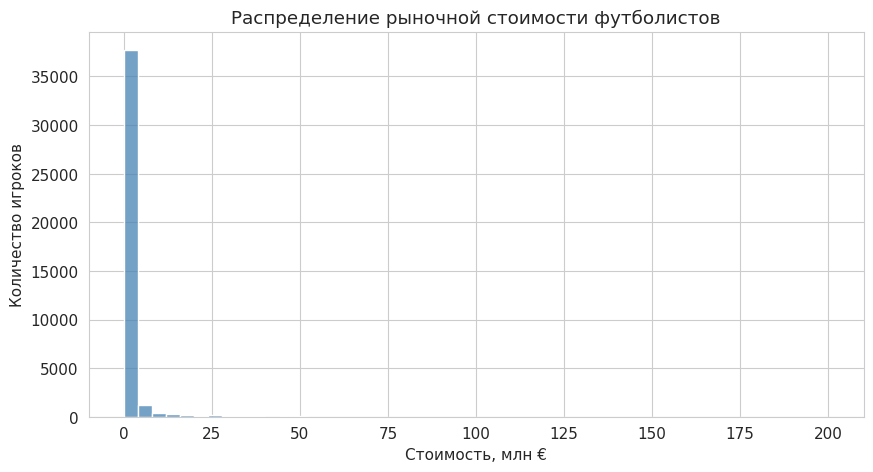

In [17]:
#  Распределение стоимости

# 1. Обычная гистограмма в млн €
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['market_value_in_eur'] / 1e6, bins=50, color='steelblue')
plt.title('Распределение рыночной стоимости футболистов')
plt.xlabel('Стоимость, млн €')
plt.ylabel('Количество игроков')
plt.savefig(f'{FIG_DIR}/01_value_distribution.png', dpi=150)
plt.show()

Что видим: почти все игроки стоят дешевле 10 млн €, и лишь единицы — дороже 50 млн €. Распределение сильно скошено вправо: «длинный хвост» из дорогих игроков.

Что это значит: средняя стоимость будет сильно завышена из-за нескольких звёзд. Поэтому в анализе лучше ориентироваться на медиану, а не на среднее. А для модели это подсказка: возможно, стоит прогнозировать логарифм стоимости, чтобы алгоритм не зацикливался на дорогих игроках.

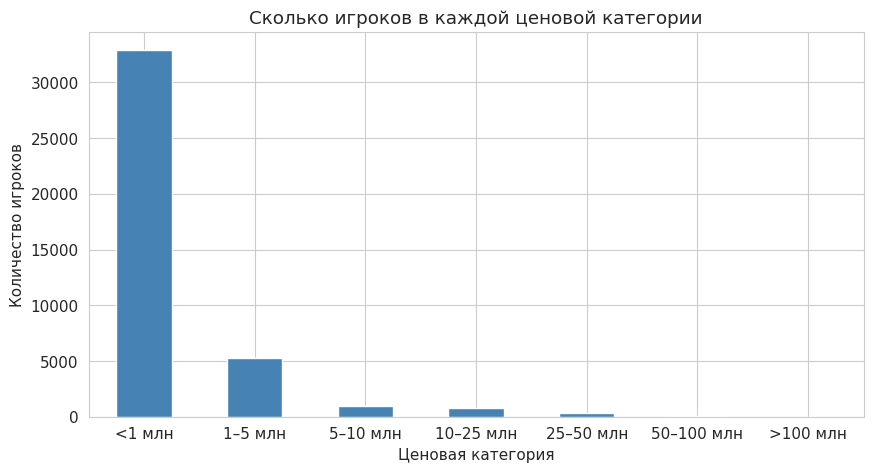

value_category
<1 млн        32896
1–5 млн        5307
5–10 млн        996
10–25 млн       783
25–50 млн       296
50–100 млн       83
>100 млн         13
Name: count, dtype: int64

Доля игроков дешевле 1 млн €: 81.5%
Доля игроков дороже 25 млн €: 1.0%


In [18]:
# 2. Сколько игроков в каждой ценовой категории
bins = [0, 1, 5, 10, 25, 50, 100, 200]
labels = ['<1 млн', '1–5 млн', '5–10 млн', '10–25 млн',
          '25–50 млн', '50–100 млн', '>100 млн']
df_clean['value_category'] = pd.cut(df_clean['market_value_in_eur'] / 1e6,
                                     bins=bins, labels=labels)

counts = df_clean['value_category'].value_counts().reindex(labels)

plt.figure(figsize=(10, 5))
counts.plot(kind='bar', color='steelblue')
plt.title('Сколько игроков в каждой ценовой категории')
plt.xlabel('Ценовая категория')
plt.ylabel('Количество игроков')
plt.xticks(rotation=0)
plt.savefig(f'{FIG_DIR}/01b_value_categories.png', dpi=150)
plt.show()

print(counts)
print(f"\nДоля игроков дешевле 1 млн €: {counts['<1 млн'] / len(df_clean) * 100:.1f}%")
print(f"Доля игроков дороже 25 млн €: {counts[['25–50 млн', '50–100 млн', '>100 млн']].sum() / len(df_clean) * 100:.1f}%")

Что видим: например, 82% игроков стоят меньше 1 млн €, а дороже 25 млн € — всего 1%. Это наглядно показывает, насколько неравномерно распределены деньги в футболе.

In [29]:
df_clean['value_mln'] = df_clean['market_value_in_eur'] / 1e6
print(df_clean['value_mln'].describe().round(2))

count    40374.00
mean         1.55
std          5.93
min          0.01
25%          0.10
50%          0.28
75%          0.75
max        200.00
Name: value_mln, dtype: float64


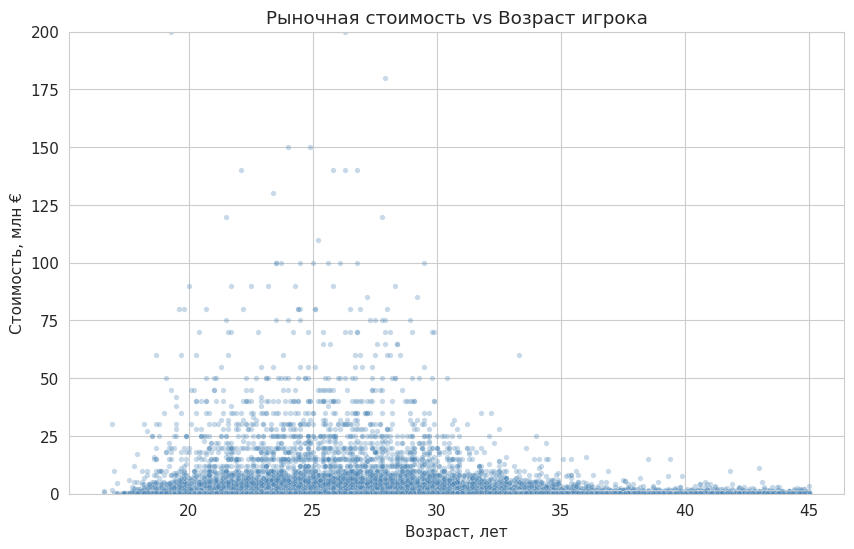

In [31]:
# График 1
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='age', y='value_mln',
                alpha=0.3, s=15, color='steelblue')
plt.title('Рыночная стоимость vs Возраст игрока')
plt.xlabel('Возраст, лет')
plt.ylabel('Стоимость, млн €')
plt.ylim(0, 200)
plt.savefig(f'{FIG_DIR}/02_value_by_age.png', dpi=150)
plt.show()

Что видим: основная масса игроков сосредоточена в возрасте 20–30 лет и стоит до 25 млн €. Самые дорогие игроки (50+ млн €) - в возрасте 21–27 лет. После 30 лет дорогих игроков почти нет.

Что это значит: клубы платят за пик карьеры и потенциал. После 30 лет игрок воспринимается как стареющий актив - цена падает.

Вывод : возраст - ключевой фактор; зависимость нелинейная (пик в 21–27 лет, спад после 30).

age_group
15–18    0.30
19–21    0.35
22–24    0.35
25–27    0.40
28–30    0.40
31–33    0.30
34–36    0.22
37+      0.15
Name: value_mln, dtype: float64


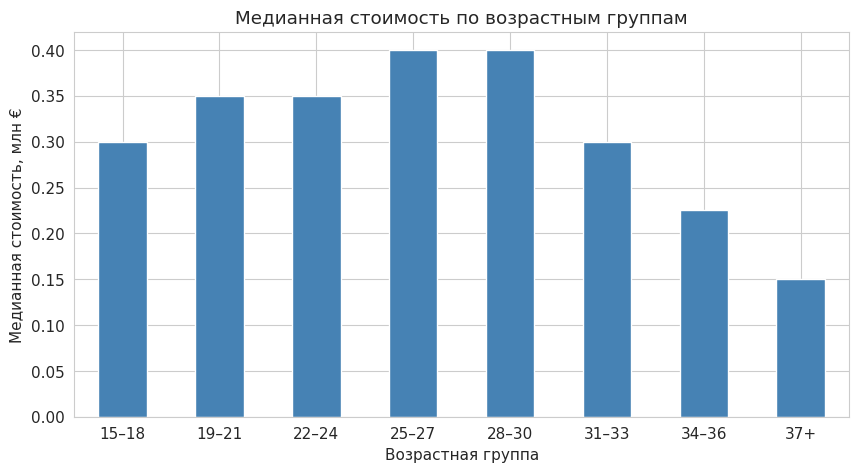

In [32]:
#  График 2
df_clean['age_group'] = pd.cut(df_clean['age'],
    bins=[15, 18, 21, 24, 27, 30, 33, 36, 45],
    labels=['15–18', '19–21', '22–24', '25–27', '28–30', '31–33', '34–36', '37+'])

age_stats = (df_clean.groupby('age_group', observed=True)['value_mln']
             .median())
print(age_stats.round(2))

plt.figure(figsize=(10, 5))
age_stats.plot(kind='bar', color='steelblue')
plt.title('Медианная стоимость по возрастным группам')
plt.xlabel('Возрастная группа')
plt.ylabel('Медианная стоимость, млн €')
plt.xticks(rotation=0)
plt.savefig(f'{FIG_DIR}/03_median_value_by_age_group.png', dpi=150)
plt.show()

Что видим: медианная стоимость растёт от группы 15-18 к группе 22-24, держится на пике в 22–27 лет, затем плавно снижается. В группе 37+ - минимальные значения.

Что это значит: ценовой пик игрока — 22-27 лет. Это совпадает с футбольной логикой: игрок уже показал уровень, но ещё не начал терять физические кондиции.

Вывод : медианная стоимость достигает максимума в 22–27 лет и снижается после 30.

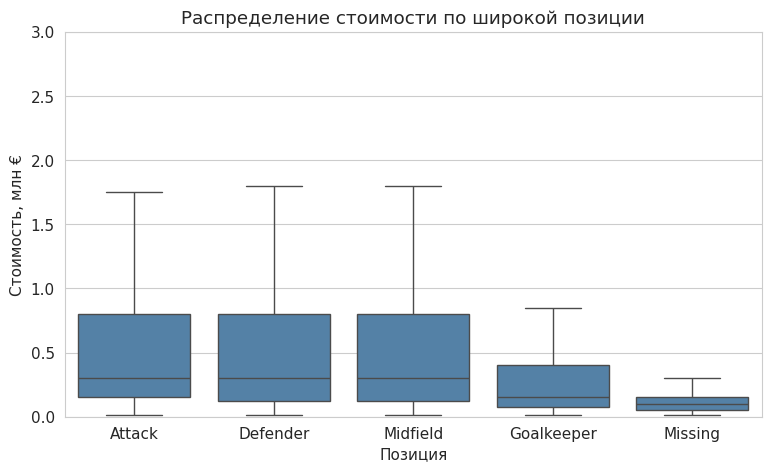

position
Attack        0.30
Defender      0.30
Goalkeeper    0.15
Midfield      0.30
Missing       0.10
Name: value_mln, dtype: float64


In [36]:
#  График 3
plt.figure(figsize=(9, 5))
order = (df_clean.groupby('position')['value_mln']
         .median().sort_values(ascending=False).index)
sns.boxplot(data=df_clean, x='position', y='value_mln',
            order=order, showfliers=False, color='steelblue')
plt.title('Распределение стоимости по широкой позиции')
plt.xlabel('Позиция')
plt.ylabel('Стоимость, млн €')
plt.ylim(0, 3)
plt.savefig(f'{FIG_DIR}/04a_value_by_position.png', dpi=150)
plt.show()

print((df_clean.groupby('position')['value_mln'].median()).round(2))

Что видим: медианная стоимость примерна одинакова у позиции Attack, Defender, Miedfield ниже - Goalkeeper..

Что это значит: атакующие игроки - самый дорогой товар на рынке: они напрямую влияют на результат (голы), их меньше, и за них конкурируют богатые клубы. Но из-за количества Defender и Miedfield они тоже примерно равны по медианной стоимости. Вратари ценятся ниже, хотя их вклад в игру не меньше.

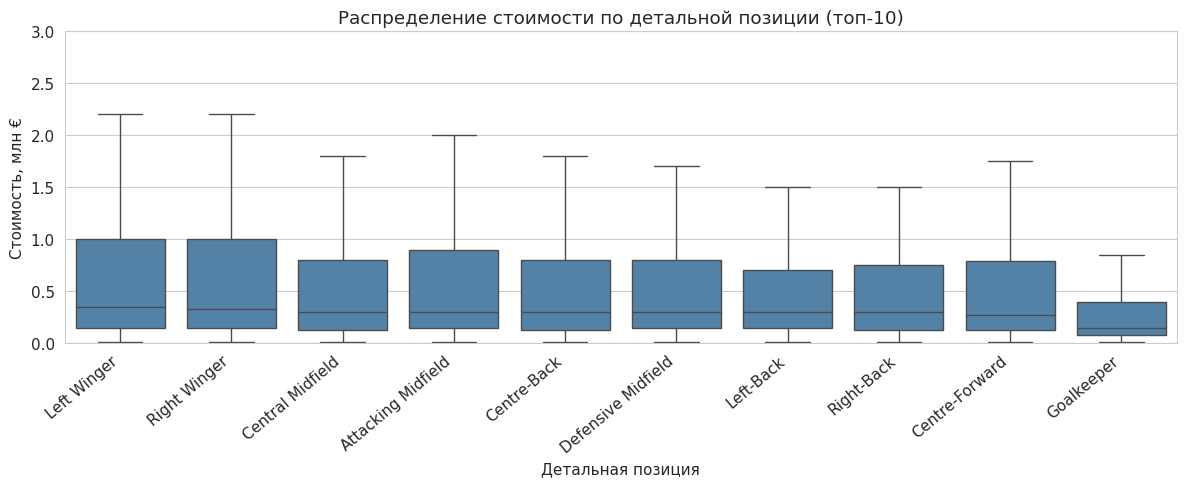

sub_position
Left Winger           0.35
Right Winger          0.32
Central Midfield      0.30
Attacking Midfield    0.30
Centre-Back           0.30
Defensive Midfield    0.30
Left-Back             0.30
Right-Back            0.30
Centre-Forward        0.28
Goalkeeper            0.15
Name: value_mln, dtype: float64


In [38]:
# График 4
top_sub = df_clean['sub_position'].value_counts().head(10).index
df_sub = df_clean[df_clean['sub_position'].isin(top_sub)]

plt.figure(figsize=(12, 5))
order = (df_sub.groupby('sub_position')['value_mln']
         .median().sort_values(ascending=False).index)
sns.boxplot(data=df_sub, x='sub_position', y='value_mln',
            order=order, showfliers=False, color='steelblue')
plt.xticks(rotation=40, ha='right')
plt.title('Распределение стоимости по детальной позиции (топ-10)')
plt.xlabel('Детальная позиция')
plt.ylabel('Стоимость, млн €')
plt.ylim(0, 3)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04b_value_by_sub_position.png', dpi=150)
plt.show()

print((df_sub.groupby('sub_position')['value_mln'].median())
      .sort_values(ascending=False).round(2))

Что видим: среди детальных позиций дороже всего -  Attacking Midfield / Right Winger/ Left Winger. Дешевле — Left-Back и Goalkeeper.


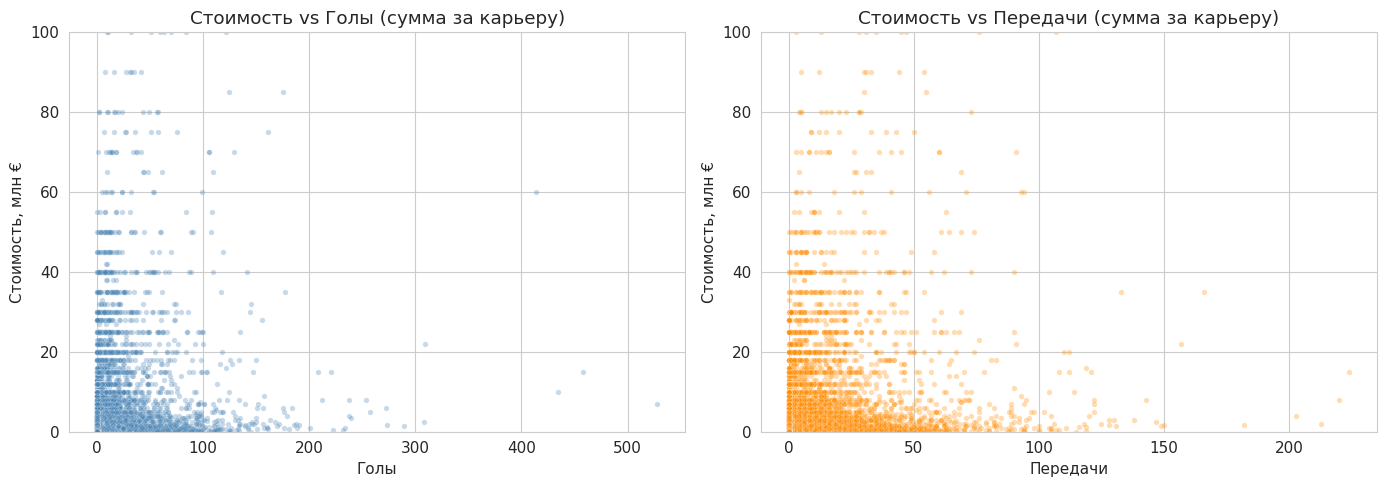

Корреляция с ценой :
goals                  0.340
assists                0.338
appearances            0.347
minutes_played         0.340
age                   -0.232
height_in_cm          -0.008
market_value_in_eur    1.000
Name: market_value_in_eur, dtype: float64


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Голы
sns.scatterplot(data=df_clean, x='goals', y='value_mln',
                alpha=0.3, s=15, ax=axes[0], color='steelblue')
axes[0].set_title('Стоимость vs Голы (сумма за карьеру)')
axes[0].set_xlabel('Голы')
axes[0].set_ylabel('Стоимость, млн €')
axes[0].set_ylim(0, 100)

# Передачи
sns.scatterplot(data=df_clean, x='assists', y='value_mln',
                alpha=0.3, s=15, ax=axes[1], color='darkorange')
axes[1].set_title('Стоимость vs Передачи (сумма за карьеру)')
axes[1].set_xlabel('Передачи')
axes[1].set_ylabel('Стоимость, млн €')
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_value_by_goals_assists.png', dpi=150)
plt.show()

print("Корреляция с ценой :")
print(df_clean[['goals', 'assists', 'appearances', 'minutes_played',
                'age', 'height_in_cm', 'market_value_in_eur']]
      .corr(method='spearman')['market_value_in_eur'].round(3))

Что видим: точки образуют облако, в котором при росте голов и передач стоимость в среднем растёт, но разброс огромный: есть игроки с 0 голов и ценой 20+ млн € (молодые таланты, защитники), и есть игроки с 100+ голов и ценой ниже 5 млн € (ветераны из слабых лиг).

Что это значит: голы и передачи - важные, но не единственные факторы. На цену сильно влияют возраст, лига, позиция и потенциал. Простая корреляция голов с ценой умеренная.

Вывод : статистика результативных действий положительно связана с ценой, но объясняет лишь часть разброса.

In [45]:
# Создаём подпись "Страна — Лига", чтобы не сливались одинаковые названия
df_clean['league_label'] = (
    df_clean['country_name'].fillna('Unknown') + ' — ' +
    df_clean['competition_name'].fillna('Unknown')
)

# Посмотрим, какие подписи получились (топ-20 по числу игроков)
print(df_clean['league_label'].value_counts().head(20))

league_label
Türkiye — super-lig                       2893
Italy — serie-a                           2860
Unknown — Unknown                         2714
Greece — super-league-1                   2381
Portugal — liga-portugal                  2310
Russia — premier-liga                     2048
Netherlands — eredivisie                  1968
Spain — laliga                            1953
Belgium — jupiler-pro-league              1894
France — ligue-1                          1875
England — premier-league                  1857
Ukraine — premier-liga                    1840
Scotland — scottish-premiership           1786
Germany — bundesliga                      1666
Denmark — superliga                       1419
Argentina — torneo-apertura                919
United States — major-league-soccer        820
Brazil — campeonato-brasileiro-serie-a     704
Japan — j1-league                          646
Poland — pko-bp-ekstraklasa                542
Name: count, dtype: int64


/tmp/ipykernel_2705/1391933185.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
/tmp/ipykernel_2705/1391933185.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')


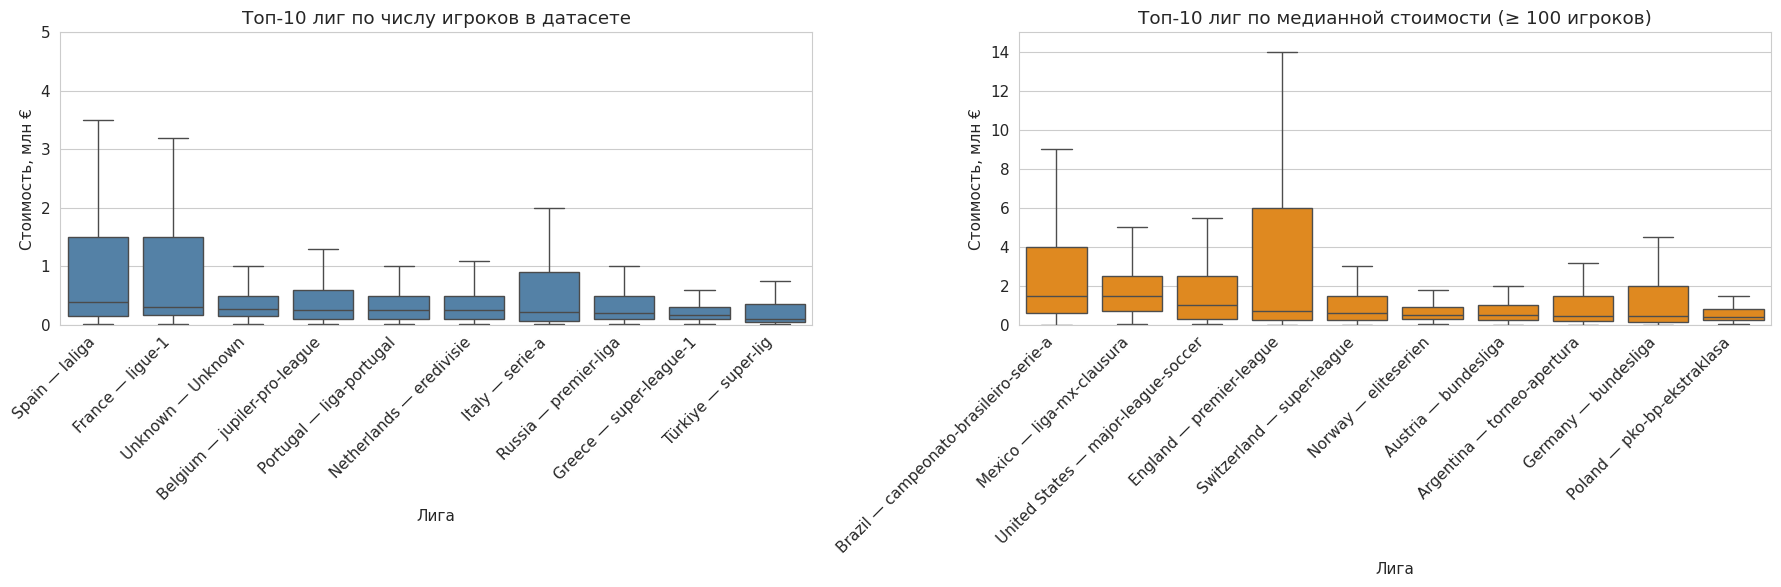

Левая панель - медианы (топ-10 по числу):
league_label
Spain — laliga                  0.40
France — ligue-1                0.30
Unknown — Unknown               0.28
Belgium — jupiler-pro-league    0.25
Portugal — liga-portugal        0.25
Netherlands — eredivisie        0.25
Italy — serie-a                 0.22
Russia — premier-liga           0.20
Greece — super-league-1         0.18
Türkiye — super-lig             0.10
Name: value_mln, dtype: float64

Правая панель - медианы (топ-10 по медианной стоимости):
league_label
Brazil — campeonato-brasileiro-serie-a    1.50
Mexico — liga-mx-clausura                 1.50
United States — major-league-soccer       1.00
England — premier-league                  0.70
Switzerland — super-league                0.60
Norway — eliteserien                      0.50
Austria — bundesliga                      0.50
Argentina — torneo-apertura               0.45
Germany — bundesliga                      0.45
Poland — pko-bp-ekstraklasa               0.40
Na

In [55]:
#  Левая панель: топ-10 по числу игроков
top_count = df_clean['league_label'].value_counts().head(10).index
df_left = df_clean[df_clean['league_label'].isin(top_count)].copy()
order_left = (df_left.groupby('league_label')['value_mln']
              .median().sort_values(ascending=False).index)

# Правая панель: топ-10 по медианной стоимости (>= 100 игроков)
league_stats = (df_clean.groupby('league_label')['value_mln']
                .agg(['median', 'count'])
                .query('count >= 100')
                .sort_values('median', ascending=False)
                .head(10))
top_median = league_stats.index
df_right = df_clean[df_clean['league_label'].isin(top_median)].copy()

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Левая панель
sns.boxplot(data=df_left, x='league_label', y='value_mln',
            order=order_left, showfliers=False, color='steelblue', ax=axes[0])
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].set_title('Топ-10 лиг по числу игроков в датасете')
axes[0].set_xlabel('Лига')
axes[0].set_ylabel('Стоимость, млн €')
axes[0].set_ylim(0, 5)

# Правая панель
sns.boxplot(data=df_right, x='league_label', y='value_mln',
            order=top_median, showfliers=False, color='darkorange', ax=axes[1])
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].set_title('Топ-10 лиг по медианной стоимости (≥ 100 игроков)')
axes[1].set_xlabel('Лига')
axes[1].set_ylabel('Стоимость, млн €')
axes[1].set_ylim(0, 15)

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/06_value_by_competition.png', dpi=150)
plt.show()

#  Числа для подписи
print("Левая панель - медианы (топ-10 по числу):")
print((df_left.groupby('league_label')['value_mln'].median())
      .sort_values(ascending=False).round(2))

print("\nПравая панель - медианы (топ-10 по медианной стоимости):")
print(league_stats['median'].round(2))

Что видим:на левом графике - топ-10 лиг по числу игроков в датасете. Здесь лидируют лиги с наибольшим числом записей: испанская Ла Лига, французская Лига 1,
бельгийская Жюпилер Про-лига, португальская Лига Португал, нидерландская
Эредивизи, итальянская Серия А, российская Премьер-лига, греческая Суперлига 1,
турецкая Суперлиг. Английская Премьер-лига (АПЛ) в этот топ не попала
в датасете по ней меньше записей, чем по некоторым другим лигам, хотя по логике должна быть она.

На правом графике - топ-10 лиг по медианной стоимости (при условии
">=" 100 игроков). Здесь картина другая: в лидеры выходят лиги с дорогими
игроками. Ла Лига, Серия А, Бундеслига и Лига 1 — в топе, потому что
там сконцентрированы звёзды.

Что это значит:

Популярность лиги в базе (число игроков) и уровень лиги (медианная
стоимость) - это разные вещи. Лига может быть представлена сотнями игроков
(включая резервистов, молодёжь, ветеранов из низших дивизионов), но медиана
будет низкой. И наоборот: АПЛ может быть представлена меньшим числом записей,
но там выше доля дорогих игроков - и медиана выше.

Нельзя судить об уровне лиги по числу игроков в
датасете. Нужно смотреть на распределение стоимости.


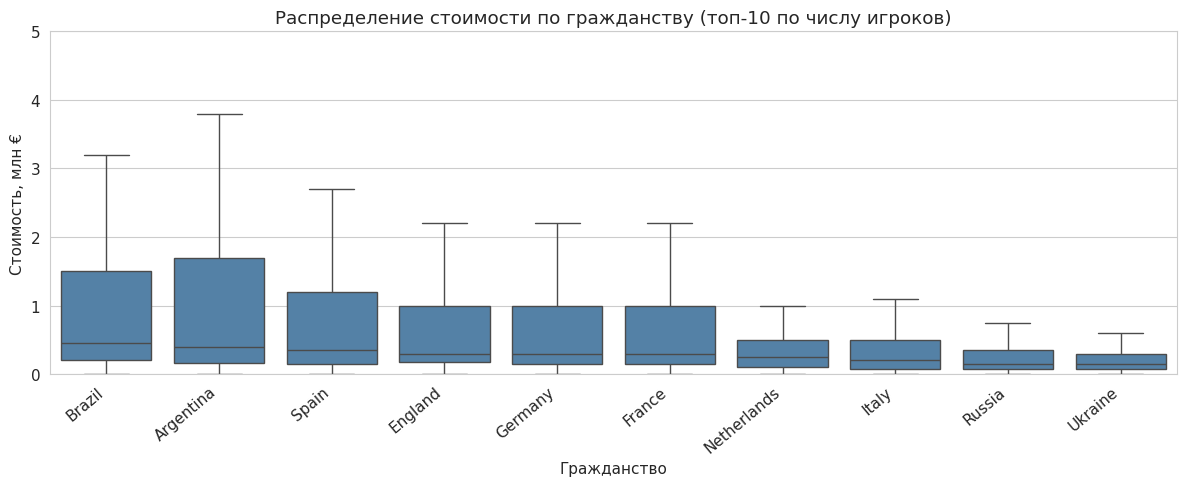

Медианная стоимость по гражданству (топ-10 по числу игроков):
country_of_citizenship
Brazil         0.45
Argentina      0.40
Spain          0.35
England        0.30
Germany        0.30
France         0.30
Netherlands    0.25
Italy          0.20
Russia         0.15
Ukraine        0.15
Name: value_mln, dtype: float64

Количество игроков по гражданству:
country_of_citizenship
Brazil         2080
Spain          1953
Italy          1839
France         1630
Russia         1482
England        1462
Argentina      1388
Netherlands    1381
Germany        1346
Ukraine        1344
Name: count, dtype: int64


In [58]:
# Топ-10 гражданств по числу игроков
top_cit = df_clean['country_of_citizenship'].value_counts().head(10).index
df_cit = df_clean[df_clean['country_of_citizenship'].isin(top_cit)].copy()

# Сортировка по медианной стоимости (по убыванию)
order_cit = (df_cit.groupby('country_of_citizenship')['value_mln']
             .median().sort_values(ascending=False).index)

#  График
plt.figure(figsize=(12, 5))
sns.boxplot(data=df_cit, x='country_of_citizenship', y='value_mln',
            order=order_cit, showfliers=False, color='steelblue')
plt.xticks(rotation=40, ha='right')
plt.title('Распределение стоимости по гражданству (топ-10 по числу игроков)')
plt.xlabel('Гражданство')
plt.ylabel('Стоимость, млн €')
plt.ylim(0, 5)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/07_value_by_citizenship.png', dpi=150)
plt.show()

#  Числа для подписи
print("Медианная стоимость по гражданству (топ-10 по числу игроков):")
print((df_cit.groupby('country_of_citizenship')['value_mln'].median())
      .sort_values(ascending=False).round(2))

print("\nКоличество игроков по гражданству:")
print(df_cit['country_of_citizenship'].value_counts().head(10))

Что видим: на графике - топ-10 гражданств по числу игроков в датасете. Медианная
стоимость выше всего у игроков с гражданством стран с сильными футбольными
школами и широким представительством в топ-лигах: как правило, это Франция,
Испания, Англия, Бразилия, Германия, Аргентина, Португалия, Италия,
Нидерланды.
Что это значит:
Гражданство - это не врождённое преимущество, а скорее
косвенный признак для:
1. Уровня футбольной школы в стране (Франция, Бразилия, Испания).
2. Лиги, где игрок выступает (французские и бразильские игроки чаще
   оказываются в топ-клубах АПЛ, Ла Лиги, Серии А).
3. Стиля игры и престижа паспорта на трансферном рынке.

То есть гражданство работает не само по себе, а через лигу и клуб. Если
в модель попадут и лига, и гражданство, они частично дублируют друг друга.

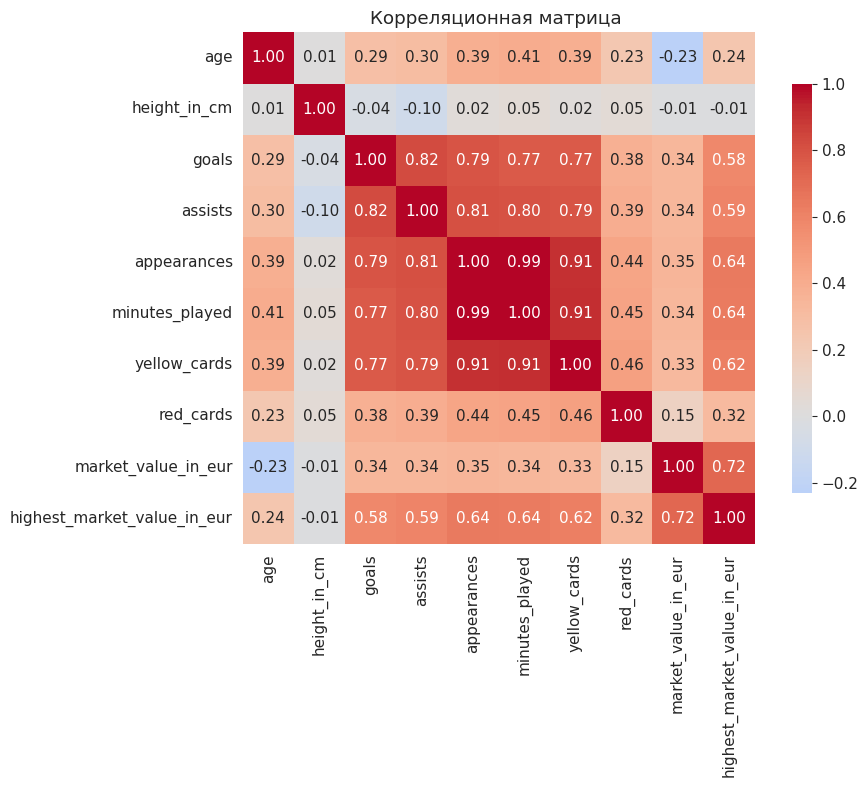

Корреляция с market_value_in_eur (Spearman), по убыванию:
market_value_in_eur            1.000
highest_market_value_in_eur    0.718
appearances                    0.347
minutes_played                 0.340
goals                          0.340
assists                        0.338
yellow_cards                   0.325
red_cards                      0.146
height_in_cm                  -0.008
age                           -0.232
Name: market_value_in_eur, dtype: float64


In [59]:
# Числовые признаки для корреляции
num_cols = ['age', 'height_in_cm', 'goals', 'assists', 'appearances',
            'minutes_played', 'yellow_cards', 'red_cards',
            'market_value_in_eur', 'highest_market_value_in_eur']
corr = df_clean[num_cols].corr(method='spearman')

# График
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': 0.8})
plt.title('Корреляционная матрица ')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/08_correlation_matrix.png', dpi=150)
plt.show()

# Числа для подписи
print("Корреляция с market_value_in_eur (Spearman), по убыванию:")
print(df_clean[num_cols].corr(method='spearman')['market_value_in_eur']
      .sort_values(ascending=False).round(3))

Что видим:

Самые сильные корреляции с `market_value_in_eur` (текущей ценой):
- `highest_market_value_in_eur` - 0.71 (очень сильная);
- `minutes_played` - 0.34 (умеренная);
- `appearances` - 0.34 (умеренная);
- `goals` - 0.34 (умеренная);
- `assists` - 0.34 (умеренная);
- `age` - -0.23 (отрицательная, потому что возрастает до центра и потом убывает).

Слабо коррелируют: `height_in_cm`, `red_cards`.

Что это значит:

1. `highest_market_value_in_eur` - исторический пик цены. Он сильно
   связан с текущей ценой,но пик часто достигается позже
   текущей оценки, и модель просто выучит текущая цена = пик, не научившись
   прогнозировать. Признак исключается.

2. `minutes_played` и `appearances` - лучшие игровые» предсказатели. Они
   отражают, насколько игрок востребован тренером: если он играет много
   минут, он ценен для клуба, а значит, и на рынке.

3. `age` слабо коррелирует линейно, но нелинейная связь сильна. Это
   аргумент добавить `age^2` как признак или использовать модели, улавливающие
   нелинейность (Random Forest, XGBoost).

4. `yellow_cards`, `red_cards`, `height_in_cm` - слабо информативны.

In [61]:
# Сохраняем финальный датасет после EDA
PROCESSED_DIR = '/content/drive/MyDrive/football_project/data/processed'
df_clean.to_csv(f'{PROCESSED_DIR}/players_clean.csv', index=False)
print("Сохранено:", df_clean.shape)
print("Колонки:", list(df_clean.columns))

Сохранено: (40374, 26)
Колонки: ['player_id', 'name', 'date_of_birth', 'position', 'sub_position', 'country_of_citizenship', 'foot', 'height_in_cm', 'current_club_id', 'current_club_name', 'current_club_domestic_competition_id', 'market_value_in_eur', 'highest_market_value_in_eur', 'goals', 'assists', 'appearances', 'minutes_played', 'yellow_cards', 'red_cards', 'competition_name', 'type', 'country_name', 'age', 'value_mln', 'age_group', 'league_label']
